<center><img src='https://drive.google.com/uc?export=view&id=12CrUdXDAiltLBT26sG7HZ_HciIhvGyT8'></center>

Spis treści:

1. klasyfikacja binarna,
2. regresja logistyczna,
3. klasyfikacja z wieloma klasami,
4. miary jakości klasyfikacji,
5. liniowa analiza dyskryminacyjna (LDA).





In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import datasets

## Klasyfikacja

Zacznijmy od bardzo prostego przykładu. Mamy informacje o poziomie określonych przeciwciał u pacjentów oraz o tym, czy są zakażeni wirusem, czy nie. Poniżej znajdują się nasze dane wejściowe i ich wizualizacja.

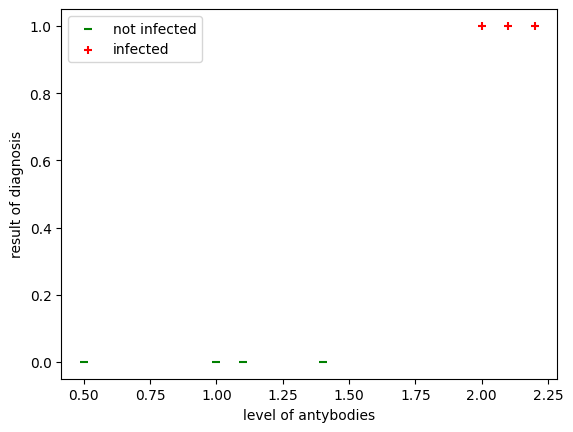

In [ ]:
# niezakażeni
X1 = [0.5, 1, 1.1, 1.4]
Y1 = np.zeros(len(X1))

# zakażeni
X2 = [2, 2.1, 2.2]
Y2 = np.ones(len(X2))

plt.scatter(X1, Y1, color="g", marker="_", label="not infected")
plt.scatter(X2, Y2, color="r", marker="+", label="infected")
plt.xlabel("level of antybodies")
plt.ylabel("result of diagnosis")
plt.legend()
plt.show()

### Klasyfikacja za pomocą regresji liniowej
Najpierw spróbujemy przeprowadzić klasyfikację za pomocą regresji liniowej (z biblioteki sklearn).

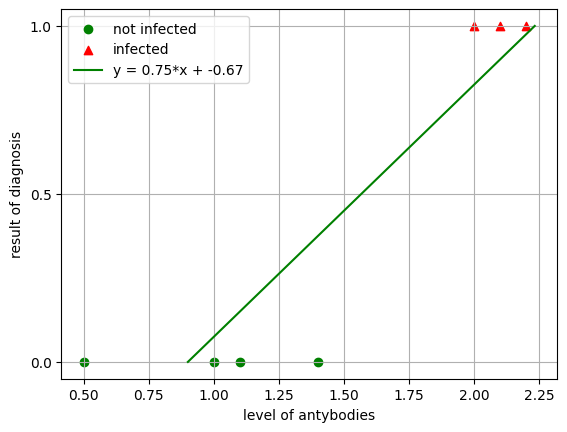

f(1.57)=0.50


In [ ]:
# niezakażeni
X1 = [0.5, 1, 1.1, 1.4]
Y1 = np.zeros(len(X1))

# zakażeni
X2 = [2, 2.1, 2.2]
Y2 = np.ones(len(X2))

plt.scatter(X1, Y1, color="g", marker="o", label="not infected")
plt.scatter(X2, Y2, color="r", marker="^", label="infected")
plt.xlabel("level of antybodies")
plt.ylabel("result of diagnosis")

# prosta regresji liniowej
X = np.append(X1, X2).reshape(-1, 1)  # zmiana kształtu z jednego wiersza na jedną kolumnę
Y = np.append(Y1, Y2)
reg = LinearRegression().fit(X, Y)

# y = ax + b
a = reg.coef_[0]
b = reg.intercept_

# x = (y-b)/a
Y = np.linspace(0, 1, 100)
X = Y/a - b/a
plt.plot(X, Y, c ="g", label=f"y = {a:.2f}*x + {b:.2f}")
plt.legend()
plt.yticks([0, 0.5, 1])
plt.grid()
plt.show()

threshold = 0.5
x_border = (threshold-b)/a
print(f"f({x_border:.2f})={threshold:.2f}")

Wydaje się, że możemy użyć predykcji z prostej regresji do klasyfikowania nowych przypadków: dla danego $x$, jeśli $reg.predict(x) \geq 0.5$, moglibyśmy uznać pacjenta za zakażonego. Działa to jednak tylko dlatego, że dane w przykładzie zostały starannie dobrane. Regresja liniowa przestaje działać, gdy dodamy bardziej skrajne pomiary albo gdy mamy więcej klas. Ponadto nie jest od razu jasne, jak bardzo prawdopodobne jest, że dana wartość należy do wybranej klasy. Zwróć uwagę, że w poniższym przykładzie niektóre punkty są źle sklasyfikowane.

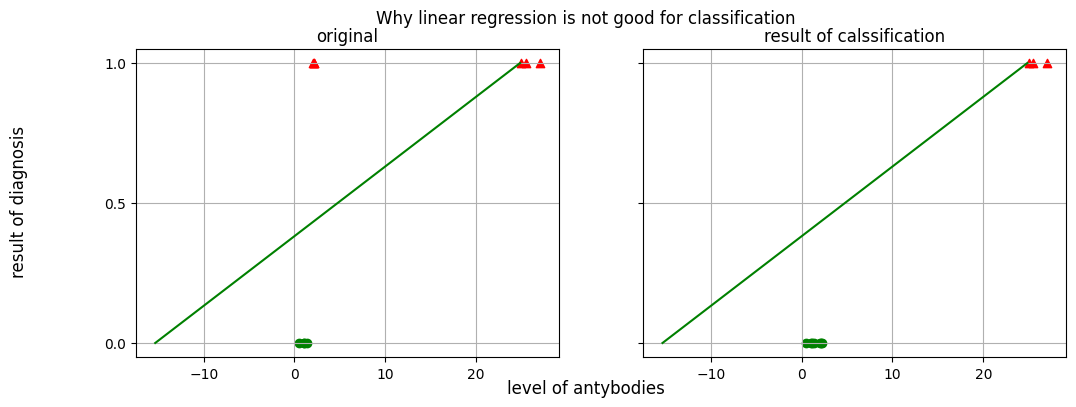

In [ ]:
# niezakażeni
X1 = [0.5, 1, 1.1, 1.4]
Y1 = np.zeros(len(X1))

# zakażeni
X2 = [2, 2.1, 2.2, 25, 25.5, 27]
Y2 = np.ones(len(X2))

# prosta regresji liniowej
X = np.append(X1, X2).reshape(-1, 1)
Y = np.append(Y1, Y2)
reg = LinearRegression().fit(X, Y)

# y = ax + b
a = reg.coef_[0]
b = reg.intercept_

# x = (y-b)/a
y = np.linspace(0, 1, 100)
x = y/a - b/a

fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(12,4))
fig.suptitle("Why linear regression is not good for classification")
fig.supxlabel("level of antybodies")
fig.supylabel("result of diagnosis")
ax1.set_yticks([0, 0.5, 1])
ax1.scatter(X1, Y1, color="g", marker="o", label="not infected")
ax1.scatter(X2, Y2, color="r", marker="^", label="infected")
ax1.plot(x, y, c ="g", label=f"y = {a:.2f}*x + {b:.2f}")
ax1.grid()
ax1.set_title("original")

# błędny wynik klasyfikacji
X = np.append(X1,X2).reshape(-1, 1)
Y = np.append(Y1,Y2)
X1 = X[reg.predict(X) < 0.5]
X2 = X[reg.predict(X) >= 0.5]

ax2.scatter(X1, np.zeros(X1.size), color="g", marker="o", label="not infected")
ax2.scatter(X2, np.ones(X2.size), color="r", marker="^", label="infected")
ax2.plot(x, y, c ="g", label=f"y = {a:.2f}*x + {b:.2f}")
ax2.grid()
ax2.set_title("result of calssification")

plt.show()

Zwróć uwagę, że duże wartości w tym przypadku nie są obserwacjami odstającymi (outlierami).

### Funkcja logistyczna

Problemy te możemy rozwiązać, stosując funkcję *logistyczną*: $\sigma(x) = \frac{1}{1 + e^{-x}} = \frac{e^x}{e^x + 1}$, która jest przykładem funkcji *sigmoidalnej* (w kształcie litery S).

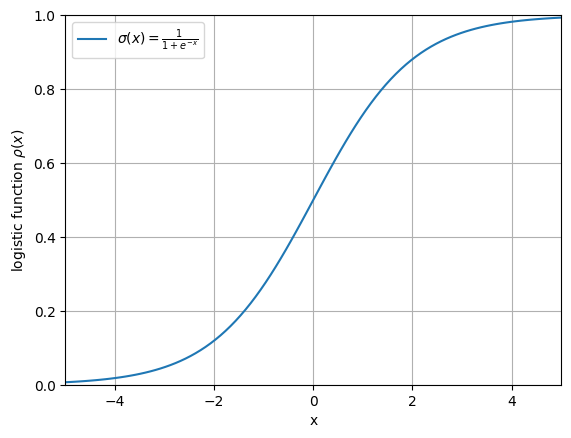

In [ ]:
x_min, x_max = -5, 5
# x_min, x_max = -10, 10
# x_min, x_max = -100, 100

x = np.linspace(x_min, x_max, 100)
y = 1/(1 + np.exp(-x))
plt.plot(x, y, label=r"$\sigma(x)= \frac{1}{1+e^{-x}}$")
plt.xlabel("x")
plt.ylabel(r"logistic function $\rho(x)$")
plt.xlim(x_min, x_max)
plt.ylim(0, 1)
plt.grid()
plt.legend()
plt.show()

### Klasyfikacja za pomocą funkcji regresji logistycznej

Zakładając przestrzeń d-wymiarową, $\mathbf{x} = (x_1, \ldots, x_d)$, oraz $n$ przykładów treningowych $\mathbf{x_1}, \ldots, \mathbf{x_n} \in \mathbb{R}_d$ z etykietami $y_1, \dots, y_n \in \{0,1\}$, mamy:
* funkcję liniową <br/> $f(\mathbf{x}) = b_d⋅x_d + \ldots + b_1⋅x_1 + b_0$, <br/> gdzie $b_d, \ldots, b_0$ to wyznaczane wagi (współczynniki),
* funkcję logistyczną $\sigma(x) = \frac{1}{1 + e^{-x}} = \frac{e^x}{e^x + 1}$,
* funkcję regresji logistycznej $\rho(\mathbf{x}) = \sigma(f(\mathbf{x})) = \frac{1}{1 + e^{-f(\mathbf{x})}} = \frac{e^{f(\mathbf{x})}}{e^{f(\mathbf{x})} + 1}$<br/>
(zauważ, że $f(\mathbf{x})=\log(\frac{\rho(\mathbf{x})}{1-\rho(\mathbf{x})})$, zob. [logit](https://en.wikipedia.org/wiki/Logit)),
* funkcję log-wiarygodności (log-likelihood) $LLF = \sum_{i=1..n}y_i \log(\rho(\mathbf{x_i}))+(1-y_i)\log(1-\rho(\mathbf{x_i}))$.

Będziemy **maksymalizować** LLF, tzn. szukać takich współczynników $b_d, \ldots, b_0$, dla których LLF jest największa.


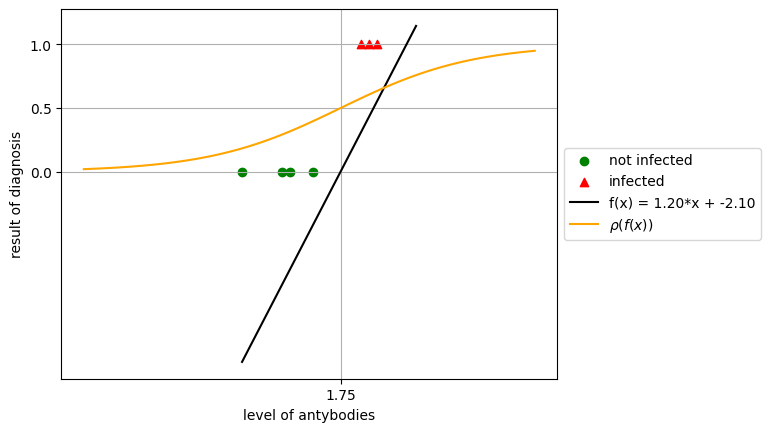

f(1.75)=0.00
g(f(1.75))=0.50


In [ ]:
# niezakażeni
X1 = [0.5, 1, 1.1, 1.4]
Y1 = np.zeros(len(X1))

# zakażeni
X2 = [2, 2.1, 2.2]
Y2 = np.ones(len(X2))

plt.scatter(X1, Y1, color="g", marker="o", label="not infected")
plt.scatter(X2, Y2, color="r", marker="^", label="infected")
plt.xlabel("level of antybodies")
plt.ylabel("result of diagnosis")

# regresja LOGISTYCZNA
X = np.append(X1, X2).reshape(-1, 1)
Y = np.append(Y1, Y2)
lr = LogisticRegression().fit(X, Y)

# y = ax + b
a = lr.coef_[0][0]
b = lr.intercept_[0]

# x = (y-b)/a
X_small = np.linspace(np.min(X), np.max(X)+0.5, 100)
X_large = np.linspace(np.min(X)-2, np.max(X)+2, 100)
Y_lin = X_small*a + b
Y_log = 1/(1+np.e**(-X_large*a - b))
plt.plot(X_small, Y_lin, c ="black", label=f"f(x) = {a:.2f}*x + {b:.2f}")
plt.plot(X_large, Y_log, c ="orange", label=r"$\rho(f(x))$")
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xticks([1.75])
plt.yticks([0, 0.5, 1])
plt.grid()
plt.show()

threshold = 0
x_border = (threshold-b)/a
print(f"f({x_border:.2f})={threshold:.2f}")
print(f"g(f({x_border:.2f}))={(1./(1+np.e**(-threshold))):.2f}")

### Zadanie 1
Wypróbuj regresję logistyczną na zbiorze danych, który sprawiał problemy regresji liniowej. Sprawdź, czy wyuczona funkcja regresji logistycznej poprawnie rozdziela dane. W tym celu narysuj wyniki klasyfikacji na danych treningowych.

In [ ]:
# niezakażeni
X1 = [0.5, 1, 1.1, 1.4]
Y1 = np.zeros(len(X1))

# zakażeni
X2 = [2, 2.1, 2.2, 25, 25.5, 27]
Y2 = np.ones(len(X2))

X = np.append(X1, X2).reshape(-1, 1)
Y = np.append(Y1, Y2)

# wytrenuj model: LogisticRegression().fit(X, Y)  (sklearn.linear_model)
lr = 0

# współczynniki funkcji liniowej odczytasz z atrybutów lr.coef_ i lr.intercept_
a = 0
b = 0

# wartości do wykresów wygeneruj przez np.linspace(...) (numpy), a funkcję logistyczną
# policz ze wzoru 1/(1+np.exp(-(a*x + b)))

X_points = 0
Y_points = 0


plt.plot(X_points, Y_points, c ="orange", label=r"$\rho(f(x))$")
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xticks([1.75])
plt.yticks([0, 0.5, 1])
plt.grid()
plt.show()

threshold = 0
x_border = (threshold-b)/a
print(f"f({x_border:.2f})={threshold:.2f}")
print(f"g(f({x_border:.2f}))={(1./(1+np.e**(-threshold))):.2f}")


### Zadanie 2
Wartość, którą regresja logistyczna przypisuje danemu wejściu, można interpretować jako prawdopodobieństwo przynależności do klasy pozytywnej (=1). Oblicz średnie dopasowane prawdopodobieństwo dla wszystkich wartości z poprzedniego przykładu i porównaj je z początkowym odsetkiem wartości w klasie pozytywnej (=1).

In [ ]:
# prawdopodobieństwa przynależności do klas zwraca metoda lr.predict_proba(X) (sklearn);
# kolumna o indeksie 1 to prawdopodobieństwo klasy pozytywnej: [:, 1]
probabilities = 0

# średnią policzysz funkcją np.mean(...) (numpy)
average_fitted_probability = 0

# odsetek klasy pozytywnej w danych to średnia z etykiet Y (klasy mają wartości 0 i 1)
initial_proportion_positive = 0

print(f"Średnie dopasowane prawdopodobieństwo: {average_fitted_probability:.4f}")
print(f"Początkowy odsetek klasy pozytywnej: {initial_proportion_positive:.4f}")


Teraz zajmiemy się przykładem dwuwymiarowym.

### Zadanie 3
Poniższy kod wczytuje zbiór danych [Iris](https://scikit-learn.org/stable/auto_examples/datasets/plot_iris_dataset.html) z biblioteki scikit-learn i rzutuje go na dwie pierwsze cechy (`Sepal length` – długość działki kielicha i `Sepal width` – szerokość działki kielicha). Wytrenuj model regresji logistycznej na tych danych. Narysuj prostą oddzielającą gatunek Setosa od pozostałych. Upewnij się, że prosta jest zgodna z wizualizacją granicy decyzyjnej uzyskaną za pomocą [DecisionBoundaryDisplay](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.DecisionBoundaryDisplay.html). Czy potrafisz wyjaśnić, jak taką prostą można uzyskać z modelu?

Podpowiedź: przyjrzyj się `LogisticRegression.coef_` i zwróć uwagę na jego kształt.

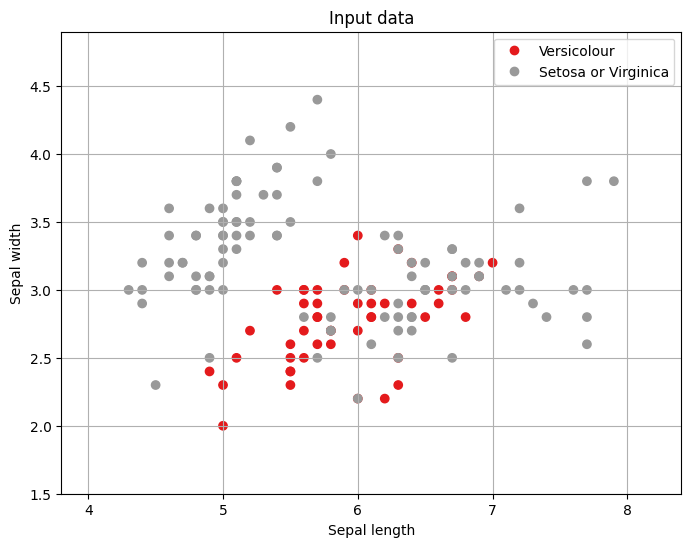

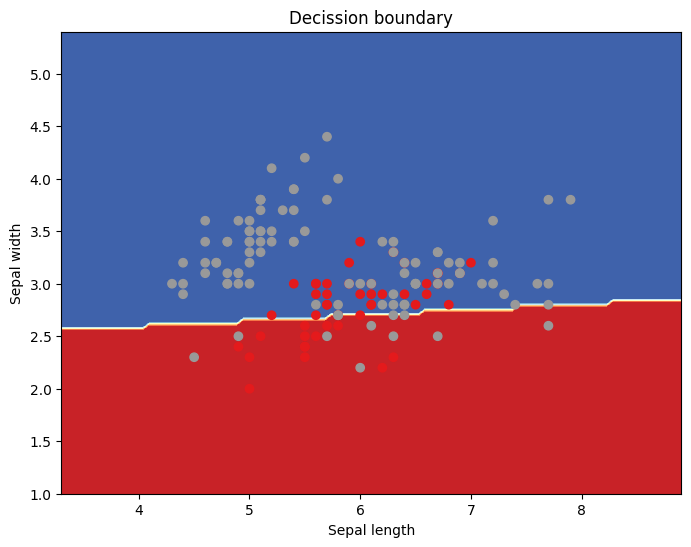

In [ ]:
iris = datasets.load_iris()
datasets.load_iris?
X = iris.data[:, :2]
Y = [int(x != 1) for x in iris.target]

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=Y, cmap=plt.cm.Set1)
plt.title("Input data")
plt.xlabel("Sepal length")
plt.ylabel("Sepal width")
plt.legend(handles=scatter.legend_elements()[0], labels=["Versicolour", "Setosa or Virginica"])
plt.grid()
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.show()

lr = LogisticRegression().fit(X, Y)

from sklearn.inspection import DecisionBoundaryDisplay
plt.figure(figsize=(8,6))
plt.title("Decission boundary")
ax = plt.gca()
DecisionBoundaryDisplay.from_estimator(
    lr,
    X,
    cmap=plt.cm.RdYlBu,
    response_method="predict",
    ax=ax,
    xlabel="Sepal length",
    ylabel="Sepal width",
)
plt.scatter(X[:, 0], X[:, 1], c=Y, cmap=plt.cm.Set1)
plt.show()

In [ ]:
# odczytaj współczynniki b1, b2 z atrybutu lr.coef_ (sprawdź najpierw lr.coef_.shape)
# oraz wyraz wolny b0 z atrybutu lr.intercept_ (sklearn.linear_model.LogisticRegression)
b1, b2 = 0, 0
b0 = 0

# granica decyzyjna to punkty, w których f(x) = b0 + b1*x1 + b2*x2 = 0 (wtedy prawdopodobieństwo wynosi 0.5);
# wyznacz z tego równania x2 jako funkcję x1;
# wartości x1 wygeneruj przez np.linspace(x_min, x_max, 100) (numpy)
x1 = 0
x2 = 0

plt.figure(figsize=(8, 6))
plt.title("Decision boundary and the separating line")
ax = plt.gca()
DecisionBoundaryDisplay.from_estimator(
    lr,
    X,
    cmap=plt.cm.RdYlBu,
    response_method="predict",
    ax=ax,
    xlabel="Sepal length",
    ylabel="Sepal width",
)
plt.scatter(X[:, 0], X[:, 1], c=Y, cmap=plt.cm.Set1)
plt.plot(x1, x2, c="black", label=f"{b0:.2f} + {b1:.2f}*x1 + {b2:.2f}*x2 = 0")
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.legend()
plt.show()


## Metryki jakości klasyfikacji
W tym przypadku klasyfikacja wygląda daleko od ideału. Sprawdźmy poprawność wyniku i to, jak pasuje on do oryginalnych danych.

In [ ]:
z = list(zip(Y,lr.predict(X)))
print(z)

matching = sum([y == prediction for y,prediction in z])
all = len(z)

print(f"matching/all = {matching/all}")  # stosunek liczby poprawnych predykcji do liczby obserwacji

[(1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 0), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (0, 1), (0, 1), (0, 1), (0, 0), (0, 1), (0, 1), (0, 1), (0, 0), (0, 1), (0, 1), (0, 0), (0, 1), (0, 0), (0, 1), (0, 1), (0, 1), (0, 1), (0, 1), (0, 0), (0, 0), (0, 1), (0, 1), (0, 0), (0, 1), (0, 1), (0, 1), (0, 1), (0, 1), (0, 1), (0, 0), (0, 0), (0, 0), (0, 1), (0, 0), (0, 1), (0, 1), (0, 1), (0, 0), (0, 1), (0, 0), (0, 0), (0, 1), (0, 0), (0, 0), (0, 1), (0, 1), (0, 1), (0, 1), (0, 0), (0, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 0), (1, 1), (1, 0), (1, 1), (1, 1), (1, 0), (1, 1), (1, 0), (1, 1), (1, 1), (1, 1), (1, 1), (1, 0), (1, 0), (1, 1), (1, 1), (1, 1), (1, 0), (1, 1),

W rzeczywistości ten stosunek nazywa się *dokładnością* (accuracy) i istnieje wbudowana metoda do jej obliczania.

In [ ]:
lr.score(X, Y)  # średnia dokładność (accuracy) na podanych danych i etykietach

0.7133333333333334

Możemy też uzyskać macierz pomyłek (confusion matrix), która zawiera informacje o prawdziwie/fałszywie pozytywnych i negatywnych wynikach. $C_{i,j}$ to liczba obserwacji z klasy $i$, które zostały przypisane do klasy $j$. W przypadku klasyfikacji binarnej daje to:
* prawdziwie negatywne (true negatives) w $C_{0,0}$ (lewy górny róg),
* fałszywie negatywne (false negatives) w $C_{1,0}$ (lewy dolny róg),
* fałszywie pozytywne (false positives) w $C_{0,1}$ (prawy górny róg),
* prawdziwie pozytywne (true positives) w $C_{1,1}$ (prawy dolny róg).

W naszym przykładzie macierz pomyłek ma wymiar 2x2.


In [ ]:
C = confusion_matrix(Y, lr.predict(X))
C

array([[17, 33],
       [10, 90]])

### Zadanie 4
Na podstawie macierzy pomyłek oblicz: (1) łączną liczbę poprawnych klasyfikacji, (2) łączną liczbę błędnych klasyfikacji, (3) dokładność klasyfikacji (accuracy), (4) poziom błędu (error rate).

In [ ]:
# odczytaj elementy macierzy pomyłek C przez indeksowanie C[i][j] (opis pozycji znajdziesz powyżej)
true_negatives = 0
false_positives = 0
false_negatives = 0
true_positives = 0

# liczności klas – zsumuj odpowiednie elementy macierzy C
positives = 0            # wszystkie obserwacje, które naprawdę są pozytywne
negatives = 0            # wszystkie obserwacje, które naprawdę są negatywne
predicted_positives = 0  # wszystkie obserwacje, które model uznał za pozytywne
predicted_negatives = 0  # wszystkie obserwacje, które model uznał za negatywne
total = 0                # wszystkie obserwacje (możesz sprawdzić wynik z C.sum() z numpy)

correct = 0    # (1) liczba poprawnych klasyfikacji
incorrect = 0  # (2) liczba błędnych klasyfikacji
acc = 0        # (3) dokładność = poprawne / wszystkie
err = 0        # (4) poziom błędu = błędne / wszystkie

print(f"(1) poprawne klasyfikacje: {correct}")
print(f"(2) błędne klasyfikacje: {incorrect}")
print(f"(3) ACC = {100 * acc:.2f}%")
print(f"(4) ERR = {100 * err:.2f}%")

# wynik ACC możesz porównać z lr.score(X, Y)


### Zadanie 5
Na podstawie macierzy pomyłek oblicz: (1) czułość / odsetek prawdziwie pozytywnych (Sensitivity, True Positive Rate – TPR), (2) swoistość / odsetek prawdziwie negatywnych (Specificity, True Negative Rate – TNR), (3) precyzję / wartość predykcyjną dodatnią (Precision, Positive Predictive Value – PPV), (4) wartość predykcyjną ujemną (Negative Predictive Value – NPV).

In [ ]:
# skorzystaj ze zmiennych z poprzedniego zadania (true_positives, positives, predicted_positives itd.)
TPR = 0  # czułość: jaka część obserwacji naprawdę pozytywnych została rozpoznana jako pozytywne
TNR = 0  # swoistość: jaka część obserwacji naprawdę negatywnych została rozpoznana jako negatywne
PPV = 0  # precyzja: jaka część obserwacji uznanych przez model za pozytywne naprawdę jest pozytywna
NPV = 0  # jaka część obserwacji uznanych przez model za negatywne naprawdę jest negatywna

print(f"TPR = {100 * TPR:.2f}%")
print(f"TNR = {100 * TNR:.2f}%")
print(f"PPV = {100 * PPV:.2f}%")
print(f"NPV = {100 * NPV:.2f}%")

# wyniki możesz sprawdzić funkcjami recall_score(...) i precision_score(...) z sklearn.metrics
# (trzeba je zaimportować; recall_score(Y, lr.predict(X), pos_label=0) to swoistość)


Możemy też wygenerować następujący raport klasyfikacji:

In [ ]:
print(classification_report(Y, lr.predict(X)))

              precision    recall  f1-score   support

           0       0.63      0.34      0.44        50
           1       0.73      0.90      0.81       100

    accuracy                           0.71       150
   macro avg       0.68      0.62      0.62       150
weighted avg       0.70      0.71      0.69       150



Więcej o miarach i zależnościach między nimi przeczytasz na [Wikipedii](https://en.wikipedia.org/wiki/Positive_and_negative_predictive_values) oraz w tym [artykule](https://www.sciencedirect.com/science/article/pii/S0306457309000259).

### Wieloklasowa regresja logistyczna

Ogólną i powszechnie stosowaną metodą radzenia sobie z wieloma klasami jest wytrenowanie regresji osobno dla każdej klasy, a następnie zastosowanie *kodowania softmax*:

$$P(Y = k \ | \ X = x) = \frac{e^{\beta_{k,0} + \beta_{k,1} x_1 + \ldots + \beta_{k,d} x_d}}{\sum_{j=1}^K e^{\beta_{j,0} + \beta_{j,1} x_1 + \ldots + \beta_{j,d} x_d}}$$

Jako wynik klasyfikacji wybieramy wtedy klasę o największym prawdopodobieństwie.




### Przygotowanie danych do analizy w praktyce
Dotychczas trenowaliśmy modele na całym zbiorze danych i w żaden sposób ich nie przygotowywaliśmy. W rzeczywistych zastosowaniach zawsze powinniśmy rozważyć następujące kroki:
1. oczyszczenie danych,
2. sprawdzenie, czy metoda wymaga skalowania cech (regresja logistyczna tego nie wymaga, ale skalowanie ma korzystne skutki: poprawia zbieżność algorytmów optymalizacji opartych na gradiencie i sprawia, że techniki regularyzacji, takie jak L1 i L2, działają jednakowo na wszystkie cechy),
3. podział danych na zbiór treningowy i testowy, aby uniknąć przeuczenia (overfittingu),
4. sprawdzenie, czy nie doszło do przeuczenia, oraz ocenę jakości otrzymanego modelu.

### Zadanie 6
Wytrenuj model regresji logistycznej dla zbioru Iris, używając wszystkich cech i wszystkich klas. Wykonaj wszystkie zalecane kroki. Wyjaśnij, w jaki sposób w modelu uwzględnione są różne klasy. Czy wartości liczbowe, które przypisujemy klasom, mają znaczenie?

Podpowiedź: użyj [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) i [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).

In [ ]:
iris = datasets.load_iris()
iris_X = iris['data']
iris_Y = iris['target']

# podział na zbiór treningowy i testowy: train_test_split(X, Y, test_size=...) (sklearn.model_selection)
X_train, X_test, Y_train, Y_test = 0, 0, 0, 0

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Y_train shape: {Y_train.shape}")
print(f"Y_test shape: {Y_test.shape}\n")

# skalowanie cech: StandardScaler() (sklearn.preprocessing);
# dopasuj go do zbioru treningowego metodą .fit_transform(...), a zbiór testowy przekształć metodą .transform(...)
scaler = 0
X_train = 0
X_test = 0

# trening: LogisticRegression().fit(...) (sklearn.linear_model)
lr = 0

# przeuczenie: porównaj dokładność lr.score(...) na zbiorze treningowym i testowym
train_acc = 0
test_acc = 0
print(f"Dokładność na zbiorze treningowym: {train_acc:.4f}")
print(f"Dokładność na zbiorze testowym: {test_acc:.4f}\n")

# predykcja na zbiorze testowym: lr.predict(...)
Y_pred = 0
print(classification_report(Y_test, Y_pred))
print(confusion_matrix(Y_test, Y_pred))

# jak model obsługuje wiele klas? sprawdź kształty lr.coef_ i lr.intercept_ oraz wynik lr.predict_proba(X_test)


## Liniowa analiza dyskryminacyjna (LDA)

Liniowa analiza dyskryminacyjna (LDA, Linear Discriminant Analysis) to kolejna metoda, której można użyć do klasyfikacji. Zakładamy tu, że dane w poszczególnych klasach mają rozkład normalny (rozkład Gaussa) z funkcją gęstości prawdopodobieństwa daną wzorem:
* $f(x|\mu, \sigma) = \frac{1}{\sigma \sqrt{2\pi} } e^{-\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)^2}$ w przypadku jednowymiarowym,
* $f({\mathbf x}|\boldsymbol\mu, \Sigma) = \frac{1}{\sqrt{(2\pi)^k |\boldsymbol\Sigma|}} e^{-\frac 1 2 ({\mathbf x} - {\boldsymbol\mu})^\mathrm{T}{\boldsymbol\Sigma}^{-1}({\mathbf x}-{\boldsymbol\mu})}$ w pozostałych przypadkach, gdzie $k$ to liczba wymiarów, $\boldsymbol\Sigma$ to macierz kowariancji, a $|\boldsymbol\Sigma|\equiv \det\boldsymbol\Sigma$ (więcej szczegółów na [Wikipedii](https://en.wikipedia.org/wiki/Multivariate_normal_distribution)). Każda klasa może mieć własną średnią, ale zakładamy, że wszystkie klasy mają tę samą wariancję / macierz kowariancji.

Przypomnij sobie informacje o [kowariancji](https://pl.wikipedia.org/wiki/Kowariancja) i [kowariancji w przypadku wielowymiarowym](https://en.wikipedia.org/wiki/Covariance_matrix).

Czy potrafisz dostrzec w tych wzorach standaryzację (Z-score) i [odległość Mahalanobisa](https://en.wikipedia.org/wiki/Mahalanobis_distance) (dają one znormalizowaną odległość od średniej)?

Zwróć uwagę, że jeśli dane nie mają rozkładu normalnego, możesz spróbować to osiągnąć, stosując przekształcenie logarytmiczne, ale zachowaj [ostrożność](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4120293/).

Przyjrzyjmy się dokładniej zbiorowi Iris. Tym razem obejrzymy histogram długości działek kielicha (Sepal length) dla gatunków Setosa i Versicolor.

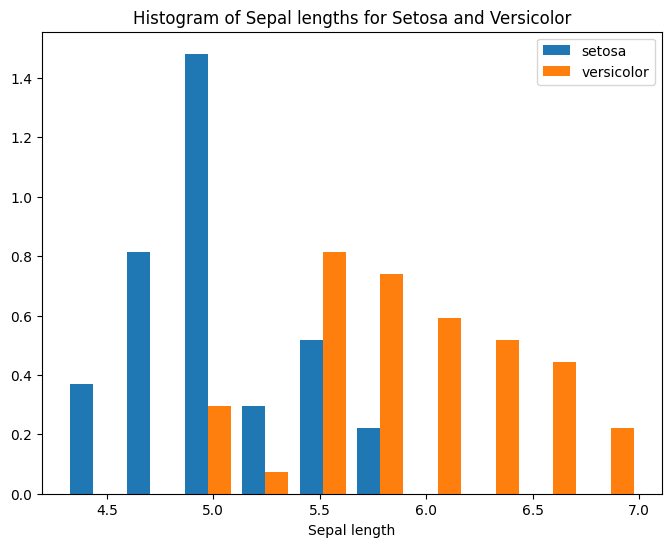

In [ ]:
iris = datasets.load_iris()  # setosa, versicolor, virginica
sepal_len = iris.data[:, 0]
# print(list(iris.target_names))  # ['setosa', 'versicolor', 'virginica']
X_se = sepal_len[iris.target == 0]
X_ve = sepal_len[iris.target == 1]
X = sepal_len[iris.target != 2]
Y = iris.target[iris.target != 2]

plt.figure(figsize=(8, 6))
plt.hist([X_se, X_ve], 10, density=True, histtype='bar', label=iris.target_names[0:2])
plt.legend()
plt.title('Histogram of Sepal lengths for Setosa and Versicolor')
plt.xlabel("Sepal length")

plt.show()

Jeśli założymy, że dane dla każdego gatunku mają rozkład normalny, otrzymamy:

In [ ]:
mu_se = np.mean(X_se)
mu_ve = np.mean(X_ve)
s_se = np.std(X_se)  # zauważ, że LDA używa jednego odchylenia standardowego dla obu klas
s_ve = np.std(X_ve)
print(f"mu_se={mu_se:.2f} s_se={s_se:.2f}\nmu_ve={mu_ve:.2f} s_ve={s_ve:.2f}")

mu_se=5.01 s_se=0.35
mu_ve=5.94 s_ve=0.51


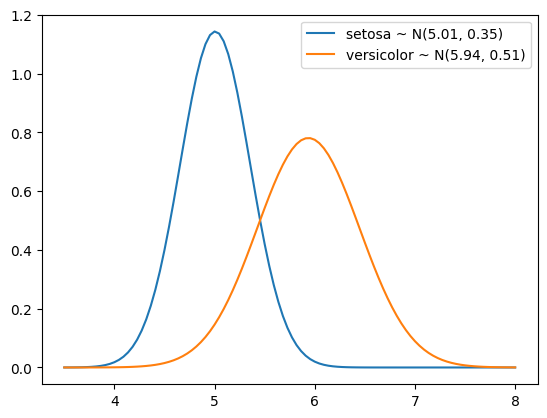

In [ ]:
def gaussian(x, mu, sig):
    return 1./(np.sqrt(2*np.pi)*sigma)*np.exp(-0.5 * (1./sigma*(x - mu))**2)

linspace = np.linspace(3.5, 8, 100)

for species, mu, sigma in [("setosa", mu_se, s_se), ("versicolor", mu_ve, s_ve)]:
    plt.plot(linspace, gaussian(linspace, mu, sigma), label=f"{species} ~ N({mu:.2f}, {sigma:.2f})")

plt.legend()
plt.show()

Dzięki temu możemy przypisywać wartości do tej klasy, dla której wiarygodność parametrów jej rozkładu jest największa (odległość od średniej jest najmniejsza).

Dla danego $x$ wiarygodność parametrów rozkładu $\mu$ i $\sigma$ jest równa gęstości prawdopodobieństwa $x$ przy tych parametrach: $L(\mu, \sigma|x) = f(x|\mu, \sigma)$. W przypadku wielowymiarowym mamy odpowiednio $\boldsymbol\mu$, $\Sigma$ oraz $L(\boldsymbol\mu, \Sigma|{\mathbf x}) = f({\mathbf x}|\boldsymbol\mu, \Sigma)$.

Prawdopodobieństwo możemy też obliczyć ze wzoru Bayesa: $P(y=Y_k) = \frac{\pi_kL(y=Y_k|x)}{\Sigma_{i}\pi_iL(y=Y_i|x)}$, gdzie $\pi_k$ to prawdopodobieństwo a priori, że obserwacja należy do klasy $k$.

Można pokazać, że jest to równoważne przypisaniu obserwacji do klasy, dla której wartość $\delta_k(x) = x \frac{\mu_k}{\sigma^2} - \frac{\mu_k^2}{2\sigma^2} + \log(\pi_k)$ jest największa. LDA przypisuje obserwację do klasy, dla której ta wartość jest największa.

Zwróć uwagę, że $\pi_k$, $\mu_k$ ($\boldsymbol\mu_k$) oraz wspólne $\sigma$ ($\boldsymbol\Sigma$) można oszacować na podstawie danych treningowych.

### Zadanie 7
Teraz narysuj histogram i rozkłady dla wszystkich 3 klas.

In [ ]:
X_se = sepal_len[iris.target == 0]
X_ve = sepal_len[iris.target == 1]
# wybierz w ten sam sposób długości działek kielicha dla trzeciego gatunku (virginica, klasa 2)
X_vi = 0

plt.figure(figsize=(8, 6))

# histogram dla trzech gatunków:
# plt.hist([...], 10, density=True, histtype='bar', label=iris.target_names) (matplotlib.pyplot)


linspace = np.linspace(3.5, 8.5, 100)
for species, X_species in zip(iris.target_names, [X_se, X_ve, X_vi]):
    # parametry rozkładu: średnia np.mean(...) i odchylenie standardowe np.std(...) (numpy)
    mu = 0
    sigma = 0
    # krzywą gęstości narysuj funkcją gaussian(linspace, mu, sigma) zdefiniowaną wyżej i plt.plot(...)


plt.legend()
plt.title("Histogram of Sepal lengths for all species")
plt.xlabel("Sepal length")
plt.show()


### Zadanie 8
Wytrenuj LDA dla zbioru Iris, używając wszystkich cech, wszystkich klas i wszystkich wymiarów. Wykonaj wszystkie zalecane kroki. Zwróć uwagę, że w przypadku LDA (podobnie jak PCA) skalowanie cech jest wymagane. Porównaj dokładność z wersją opartą na regresji logistycznej. Wyjaśnij, w jaki sposób w modelu uwzględnione są różne klasy. Czy wartości liczbowe, które przypisujemy klasom, mają znaczenie?

Podpowiedź: użyj [sklearn.discriminant_analysis.LinearDiscriminantAnalysis](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html).




In [ ]:
iris = datasets.load_iris()
iris_X = iris['data']
iris_Y = iris['target']

# podział na zbiór treningowy i testowy: train_test_split(...) (sklearn.model_selection);
# ustaw random_state, aby porównać LDA i regresję logistyczną na tym samym podziale danych
X_train, X_test, Y_train, Y_test = 0, 0, 0, 0

# skalowanie cech: StandardScaler() – .fit_transform(...) na zbiorze treningowym, .transform(...) na testowym
scaler = 0
X_train = 0
X_test = 0

# trening: LinearDiscriminantAnalysis().fit(...) (sklearn.discriminant_analysis)
lda = 0

# predykcja na zbiorze testowym: lda.predict(...)
Y_pred = 0
print(classification_report(Y_test, Y_pred))

# porównanie: wytrenuj LogisticRegression() na tych samych danych i porównaj wyniki metody .score(X_test, Y_test)
lda_acc = 0
lr_acc = 0
print(f"Dokładność LDA: {lda_acc:.4f}")
print(f"Dokładność regresji logistycznej: {lr_acc:.4f}")


## Kwadratowa analiza dyskryminacyjna (QDA)

W LDA zakładamy, że wszystkie klasy mają tę samą wariancję (istnieje wspólna macierz kowariancji), ale jeśli mamy dużo danych treningowych, możemy oszacować osobne wartości dla każdej klasy. Wtedy zmienia się definicja $\delta_k(x)$. Przypomnij sobie, że obliczaliśmy takie wartości dla wszystkich klas i wybieraliśmy klasę z największą wartością. W LDA jest to funkcja liniowa. Przy różnych wariancjach (macierzach kowariancji) w QDA już tak nie jest, ponieważ funkcja jest kwadratowa: $\delta_k(x) = -\frac{1}{2} (x-\mu_k)^T \Sigma_k^{-1} (x-\mu_k) -\frac{1}{2} \log |\Sigma_k| + \log(\pi_k)$.

Zobacz odpowiednią klasę w sklearn: [QuadraticDiscriminantAnalysis](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.QuadraticDiscriminantAnalysis.html).

### Zadanie 9
Możesz nabrać intuicji, jak zmienia się rozkład danych w zależności od parametrów, eksperymentując z poniższym przykładem. Zwróć uwagę, że jeśli dla obu klas użyjemy tej samej kowariancji, to granica (wyznaczona przez punkty o jednakowym prawdopodobieństwie przynależności do każdej z klas) jest liniowa, a w przeciwnym razie – kwadratowa. Zmieniaj parametry i upewnij się, że rozumiesz, jak działa wielowymiarowy rozkład normalny.

Podpowiedź: zajrzyj do rozdziału 4.5 *A Comparison of Classification Methods* w książce, gdzie omówiono, kiedy poszczególne klasyfikatory działają najlepiej.

In [ ]:
from matplotlib.colors import ListedColormap
import matplotlib.pylab as pl
from scipy.stats import multivariate_normal
from sklearn.utils.extmath import cartesian

def prep_color_map(cm):
  fading_map = cm(np.arange(cm.N)) # pobranie kolorów
  fading_map[:, -1] = np.linspace(0, 1, cm.N) # zmiana przezroczystości (alpha)
  fading_map = ListedColormap(fading_map) # zamiana na mapę kolorów
  return fading_map

fading_red = prep_color_map(pl.cm.Reds)
fading_blue = prep_color_map(pl.cm.Blues)


def plot_distr_and_border(mean1, cov1, mean2, cov2):
  x1 = np.random.multivariate_normal(mean1, cov1, 500000)
  x2 = np.random.multivariate_normal(mean2, cov2, 500000)
  plt.figure(figsize=(8, 6))
  plt.hist2d(x1[:, 0], x1[:, 1], bins=70, cmap=fading_blue)
  plt.hist2d(x2[:, 0], x2[:, 1], bins=70, cmap=fading_red)
  plt.grid()
  ax = plt.gca()
  xlim = ax.get_xlim()
  ylim = ax.get_ylim()
  xlin = np.linspace(xlim[0], xlim[1], 200)
  ylin = np.linspace(ylim[0], ylim[1], 200)
  grid = cartesian((xlin,ylin))

  dist1 = multivariate_normal(mean1,cov1)
  dist2 = multivariate_normal(mean2,cov2)
  pdf1 = np.reshape(dist1.pdf(grid),(xlin.size, ylin.size))
  pdf2 = np.reshape(dist2.pdf(grid),(xlin.size, ylin.size))

  border = dist1.pdf(grid) <= dist2.pdf(grid)
  data = grid[border]
  plt.tricontour(grid[:, 0], grid[:, 1], border)

  plt.show()

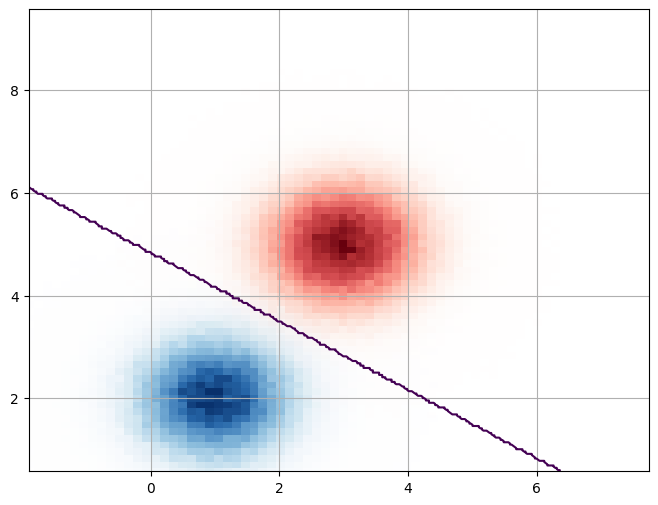

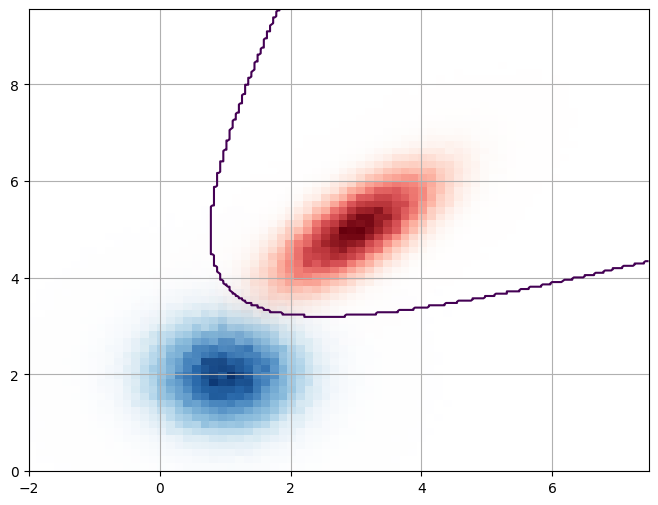

In [ ]:
mean1 = np.array([1,2])
cov1 = np.array([[1,0],[0,1]])  # cov musi być symetryczną macierzą dodatnio półokreśloną
mean2 = np.array([3,5])
cov2 = np.array([[1,0.7],[0.7,1]])  # cov musi być symetryczną macierzą dodatnio półokreśloną
plot_distr_and_border(mean1, cov1, mean2,cov1)
plot_distr_and_border(mean1, cov1, mean2,cov2)

## Naiwny klasyfikator Bayesa

Istnieje też klasyfikator oparty na twierdzeniu Bayesa, który zakłada warunkową niezależność każdej pary cech przy danej wartości klasy. Dzięki tym upraszczającym założeniom metoda ta wymaga mniej danych treningowych. Ma większe obciążenie (bias) i mniejszą wariancję.

Zobacz odpowiednią klasę w sklearn: [GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html#sklearn.naive_bayes.GaussianNB).

## Zadanie domowe
Użyj regresji logistycznej, aby wytrenować model klasyfikujący odręcznie pisane cyfry. Skorzystaj z poniższego zbioru danych. Zmierz jakość klasyfikacji swojego modelu.

[[ 0.  0.  5. ...  0.  0.  0.]
 [ 0.  0.  0. ... 10.  0.  0.]
 [ 0.  0.  0. ... 16.  9.  0.]
 ...
 [ 0.  0.  1. ...  6.  0.  0.]
 [ 0.  0.  2. ... 12.  0.  0.]
 [ 0.  0. 10. ... 12.  1.  0.]]
[0 1 2 ... 8 9 8]


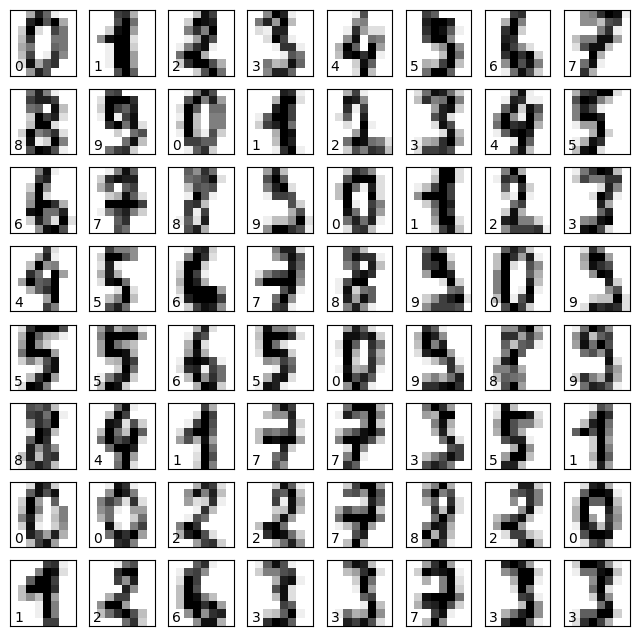

In [ ]:
from sklearn.datasets import load_digits
load_digits?
X, Y = load_digits(return_X_y=True)
print(X)
print(Y)

fig = plt.figure(figsize=(8, 8))

for i in range(64):
  ax = fig.add_subplot(8, 8, i + 1, xticks=[], yticks=[])
  ax.imshow(np.array(X[i]).reshape(8,8), cmap=plt.cm.binary, interpolation='nearest')
  # podpisanie obrazka wartością docelową (etykietą)
  ax.text(0, 7, str(Y[i]))

In [ ]:
# accuracy_score trzeba zaimportować z sklearn.metrics
from sklearn.metrics import accuracy_score

# skalowanie cech: StandardScaler() (sklearn.preprocessing)
# i podział danych: train_test_split(..., test_size=0.2) (sklearn.model_selection)
X_train, X_test, Y_train, Y_test = 0, 0, 0, 0

# model: LogisticRegression(max_iter=...) (sklearn.linear_model) – zwiększ max_iter,
# jeśli pojawi się ostrzeżenie o braku zbieżności; potem metoda .fit(...)
log_reg = 0

# predykcja: metoda .predict(...)
Y_pred = 0

# ocena: accuracy_score(...) i classification_report(...) (sklearn.metrics)
accuracy = 0
report = 0

print(f"Dokładność: {accuracy:.4f}")
print("Raport klasyfikacji:")
print(report)

# możesz też obejrzeć confusion_matrix(Y_test, Y_pred) – które cyfry model myli najczęściej?


## Dodatkowe materiały ##
* [Redukcja wymiarowości za pomocą liniowej analizy dyskryminacyjnej](https://scikit-learn.org/stable/modules/lda_qda.html#dimensionality-reduction-using-linear-discriminant-analysis)
* [Wizualizacja macierzy pomyłek](https://medium.com/@dtuk81/confusion-matrix-visualization-fc31e3f30fea)
* [Naiwny klasyfikator Bayesa](https://scikit-learn.org/stable/modules/naive_bayes.html). Zajrzyj do rozdziału 4.5 *A Comparison of Classification Methods* w książce, gdzie omówiono, kiedy poszczególne klasyfikatory działają najlepiej.
* [Uogólniony model liniowy z rozkładem Poissona](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.PoissonRegressor.html). Omówienie w rozdziale 4.6 *Generalized Linear Models* w [książce](https://hastie.su.domains/ISLP/ISLP_website.pdf).
* Generowanie losowego problemu klasyfikacji z n klasami za pomocą [sklearn.datasets.make_classification](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_classification.html).
* [DecisionBoundaryDisplay](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.DecisionBoundaryDisplay.html#sklearn.inspection.DecisionBoundaryDisplay.from_estimator)
* [RocCurveDisplay](https://scikit-learn.org/stable/visualizations.html#visualizations)
* [imbalanced-learn](https://imbalanced-learn.org/stable/index.html) – otwartoźródłowa biblioteka na licencji MIT, oparta na scikit-learn, z narzędziami do klasyfikacji przy niezbalansowanych klasach

<center><img src='https://drive.google.com/uc?id=1_utx_ZGclmCwNttSe40kYA6VHzNocdET' height="60">

AI TECH - Akademia Innowacyjnych Zastosowań Technologii Cyfrowych. Program Operacyjny Polska Cyfrowa na lata 2014-2020
<hr>

<img src='https://drive.google.com/uc?id=1BXZ0u3562N_MqCLcekI-Ens77Kk4LpPm'>


Projekt współfinansowany ze środków Unii Europejskiej w ramach Europejskiego Funduszu Rozwoju Regionalnego
Program Operacyjny Polska Cyfrowa na lata 2014-2020,
Oś Priorytetowa nr 3 "Cyfrowe kompetencje społeczeństwa" Działanie  nr 3.2 "Innowacyjne rozwiązania na rzecz aktywizacji cyfrowej".   
Tytuł projektu:  „Akademia Innowacyjnych Zastosowań Technologii Cyfrowych (AI Tech)”
    </center>